[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alanturin-g/Computational_Neuroscience_UNITO_2026/blob/main/Perotti_3_ML_done_right.ipynb)

In [ ]:
# Yes, again..
# File -> Save a copy in Drive
from google.colab import auth; auth.authenticate_user()
from google.colab import drive; drive.mount('/content/drive')

# Lesson 3 - Machine learning, done right

**Computational Neuroscience 2026/27 · Alan Perotti**

Lesson 2 gave the ideas. Today we write one complete machine learning analysis, one small step at a time, in the correct order. The dataset is the passengers of the Titanic: for each passenger we know a few facts (class, sex, age, ...) and whether they survived. The task is to predict survival.

Nothing here is new: every step applies a rule from the "Good practices" slide of Lesson 2. The new part is that you see each rule written as code.

## Learning goals

- Follow a complete analysis in the correct order: look, split, baseline, pipeline, cross-validation, tuning, final test
- Look at the data before modelling: classes, missing values, scales
- Split first, and keep the test set locked until the very end
- Put preprocessing (filling missing values, scaling, encoding) inside a pipeline, so that nothing from the test set leaks into training
- Compare models with cross-validation and tune hyperparameters with a grid search
- Report a mean and a spread, not a single number
- Evaluate the chosen model once on the test set and read the result

## The map of the lesson

| Part | What we do | Rule of the "Good practices" slide |
|---|---|---|
| 1 | Look at the data | Look at the data first. Always doubt |
| 2 | Split | Split first, stratified. The test set is scored once |
| 3 | Baseline, metric | Compare with a baseline. Look beyond accuracy |
| 4 | Pipeline | Rescale with a scaler fitted on the train set only, inside a pipeline |
| 5 | Compare models, balance the classes | Compare train and validation scores. Balance the classes on the train set only |
| 6 | Tune | Choose hyperparameters with cross-validation, never with the test set |
| 7 | Seeds | Set the seeds. Report a mean and a spread |
| 8 | Final test | The test set is scored once. A perfect score is a warning |
| 9 | Importance | (a caution, not a rule) a model carries information, it does not prove causes |

---

## The big picture: what are we trying to do, and why so many steps?

**The goal.** We want a model that predicts well on passengers it has never seen. The passengers we already have are not interesting: we know what happened to them.

**The difficulty.** We cannot measure "the performance on unseen passengers" directly. We can only imitate it: we hide some passengers, and we score the model on them. This estimate is honest only if the hidden passengers had *no influence* on anything we did: not on the model, not on the preprocessing, not on the choice of the settings.

**The idea of the whole lesson.** Every step below either protects this honest estimate, or helps to build a better model.

| Step | In one sentence |
|---|---|
| Look at the data | know what we are working with |
| Split | hide the test set |
| Baseline | know what "good" means: the score of the trivial model |
| Pipeline | learn the preprocessing on the training rows only |
| Cross-validation | compare models without using the test set |
| Tuning | choose the settings, still without the test set |
| Seeds | know how much a score depends on chance |
| Final test | measure once, on the hidden passengers |

The flow of the data:

```
all passengers
  |
  |-- test set (30%) ........ locked until the very end
  |
  |-- train set (70%)
        |-- cross-validation: fit on 4 parts, validate on 1 part, 5 times
        |-- here we compare the models and tune the hyperparameters (and only here)
  |
  final: refit the best model on the whole train set, score it once on the test set
```

# Part 0 - The tools

> **What we do:** import the libraries.
>
> **Why:** Python tools live in libraries. We load them once, at the top, so that the rest of the notebook can use them.

We import everything at the top, as good practice. You do not need to understand each line now: we meet every tool when we use it, and we say what it does at that moment.

- `numpy`, `pandas`: numbers and tables
- `matplotlib`, `seaborn`: plots
- `train_test_split`: splits the data in train and test
- `StratifiedKFold`, `RepeatedStratifiedKFold`, `cross_validate`, `cross_val_score`: cross-validation
- `validation_curve`, `GridSearchCV`: look at, and choose, hyperparameters
- `SimpleImputer`, `StandardScaler`, `OneHotEncoder`: preprocessing steps
- `ColumnTransformer`, `make_pipeline`: chain the preprocessing steps and the model
- `KNeighborsClassifier`, `RandomForestClassifier`, `MLPClassifier`, `DummyClassifier`: the models
- `clone`: makes a fresh, unfitted copy of a model
- the `metrics` and `permutation_importance`: measure the results

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_validate, cross_val_score, validation_curve, GridSearchCV)
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

import warnings
warnings.filterwarnings('ignore')

# Part 1 - Look at the data

> **What we do:** inspect the table: its size, the types of the columns, the missing values, the balance of the classes, the scales.
>
> **Why:** every later choice depends on what we find here. A model fitted on a table we did not understand gives numbers we cannot interpret.

**Rule: look at the data first.** Before any model, we want to know what is in the table: how many rows, what kind of columns, how many missing values, which scales. Every decision later depends on these answers.

## 1.1 Load the data

The Titanic dataset comes with the `seaborn` library. We keep eight columns.

| Column | Meaning |
|---|---|
| `survived` | **the label**: 1 if the passenger survived, 0 if not |
| `pclass` | ticket class: 1, 2 or 3 |
| `sex` | `male` or `female` |
| `age` | age in years |
| `sibsp` | number of siblings or spouses on board |
| `parch` | number of parents or children on board |
| `fare` | the price of the ticket |
| `embarked` | the port where the passenger boarded: `C`, `Q` or `S` |

Each row is one passenger. The task is a **classification** problem: predict `survived` (0 or 1) from the other seven columns.

In [10]:
# Load the Titanic table from the seaborn library (needs an internet connection)
titanic = sns.load_dataset('titanic')
# Keep only the columns we need: the label (survived) and 7 features
df = titanic[['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']]
# Show the first 5 rows
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


## 1.2 How big is it, and what is in it?

`shape` gives (rows, columns). `info()` lists each column with its type and the number of values that are **not** missing.

In [11]:
# shape = (number of rows, number of columns)
print("Shape (rows, columns):", df.shape)
print()
# info() lists every column with its type and the number of non-missing values
df.info()

Shape (rows, columns): (891, 8)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  891 non-null    int64  
 1   pclass    891 non-null    int64  
 2   sex       891 non-null    object 
 3   age       714 non-null    float64
 4   sibsp     891 non-null    int64  
 5   parch     891 non-null    int64  
 6   fare      891 non-null    float64
 7   embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(2)
memory usage: 55.8+ KB


**What to notice.** The table has 891 rows. Most columns have 891 non-null values, but `age` has fewer, and `embarked` has two fewer. Some values are missing. Also, `sex` and `embarked` are `object` columns: they contain text, not numbers. Most models cannot use text directly.

## 1.3 How many passengers survived, and how many died?

The label is `survived`. We count how many rows have 0 and how many have 1.

In [12]:
# How many passengers died (0) and survived (1)?
print("Counts:")
print(df['survived'].value_counts())
print()
# The same, as proportions (they sum to 1)
print("Proportions:")
print(df['survived'].value_counts(normalize=True).round(3))

Counts:
survived
0    549
1    342
Name: count, dtype: int64

Proportions:
survived
0    0.616
1    0.384
Name: proportion, dtype: float64


**What to notice.** About 38% of the passengers survived and about 62% died. The classes are not equally frequent, but the imbalance is moderate (in Lesson 2 it was 90/10). This number is important: a model that always answers "died" would be right about 62% of the time. We will use it as a baseline in Part 3.

## 1.4 Which values are missing?

`isna()` marks the missing values, `sum()` counts them per column.

In [13]:
# isna() marks the missing values, sum() counts them for each column
missing = df.isna().sum()
# Show the counts and the percentage of rows affected
print(pd.DataFrame({'missing': missing, 'percent': (missing / len(df) * 100).round(1)}))

          missing  percent
survived        0      0.0
pclass          0      0.0
sex             0      0.0
age           177     19.9
sibsp           0      0.0
parch           0      0.0
fare            0      0.0
embarked        2      0.2


**What to notice.** 177 ages are missing (about 20% of the passengers) and 2 values of `embarked`. What can we do?

1. **Drop the rows** with a missing value. Simple, but we lose 20% of the passengers, and they may not be a random 20%.
2. **Fill the gaps** (this is called **imputation**), for example with the median age.

We choose imputation. But there is a catch: the value we use to fill the gaps (the median) is *learned from the data*. So, by Lesson 2, it must be learned on the **training set only**. For this reason we do not fill anything now. We do it inside the pipeline, in Part 4.

## 1.5 Which scales?

`describe()` gives, for each numeric column, mean, standard deviation, minimum and maximum.

In [14]:
# describe() gives count, mean, std, min, quartiles and max of each numeric column
df.describe().round(1)

,survived,pclass,age,sibsp,parch,fare
count,891.0,891.0,714.0,891.0,891.0,891.0
mean,0.4,2.3,29.7,0.5,0.4,32.2
std,0.5,0.8,14.5,1.1,0.8,49.7
min,0.0,1.0,0.4,0.0,0.0,0.0
25%,0.0,2.0,20.1,0.0,0.0,7.9
50%,0.0,3.0,28.0,0.0,0.0,14.5
75%,1.0,3.0,38.0,1.0,0.0,31.0
max,1.0,3.0,80.0,8.0,6.0,512.3


**What to notice.** The columns live on very different scales: `pclass` goes from 1 to 3, `age` from under 1 to 80, `fare` from 0 to more than 500. Models based on distances (KNN) and models trained by gradient descent (MLP) would be dominated by `fare`. We will rescale in Part 4.

## 1.6 A first look at the relation with the label

We compute the share of survivors for each value of `sex` and of `pclass`.

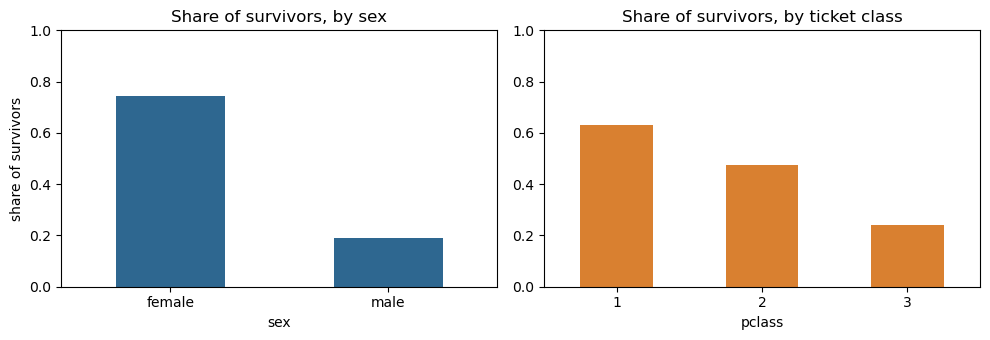

In [15]:
# Left: share of survivors for each sex. Right: for each ticket class
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

# The mean of a 0/1 column is the share of ones, here the share of survivors
df.groupby('sex')['survived'].mean().plot.bar(ax=axes[0], rot=0, color='#2E6790')
axes[0].set_title('Share of survivors, by sex')
axes[0].set_ylabel('share of survivors')
axes[0].set_ylim(0, 1)

df.groupby('pclass')['survived'].mean().plot.bar(ax=axes[1], rot=0, color='#D98030')
axes[1].set_title('Share of survivors, by ticket class')
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

**What to notice.** Women and first-class passengers survived much more often. So `sex` and `pclass` carry information about the label, and a model has something to learn. This is a description of the data: it does not say *why* (more on this in Part 9).

## 1.7 Separate the features from the label

As in Lesson 2: `X` is the table of features, `y` is the label. We also write down which columns are numeric and which are categorical, because the two kinds need different preprocessing.

`pclass` is a number with an order (1st, 2nd, 3rd), so we treat it as numeric.

We do **not** modify `X` here: it still contains missing values and text. That is on purpose.

In [16]:
# X: the features (every column except the label). y: the label to predict
X = df.drop(columns='survived')
y = df['survived']

# Numeric columns and categorical (text) columns need different preprocessing
numeric_cols = ['pclass', 'age', 'sibsp', 'parch', 'fare']
categorical_cols = ['sex', 'embarked']

print("X:", X.shape, "| y:", y.shape)

X: (891, 7) | y: (891,)


# Part 2 - Split first

> **What we do:** put 30% of the passengers aside (the test set) and do not look at them.
>
> **Why:** our goal is to know how the model will behave on *new* passengers. The only way to imitate "new" is to keep some passengers out of everything we do until the very end.

**Rule: split first, stratified. The test set is scored once, at the end.**

We now set aside a part of the passengers: the **test set**. It plays the role of "new passengers, never seen". We will not look at it, not even for a quick check, until Part 8.

Why now, and not later? Because every later step (filling gaps, choosing a model, choosing hyperparameters) *learns something from the data*. If the test rows are in the data when we learn, the test set is no longer new.

## The arguments of `train_test_split`

- `test_size=0.3`: 30% of the rows go to the test set, 70% to the train set
- `stratify=y`: both parts keep the same share of survivors as the whole dataset
- `random_state=42`: the **seed**. The split is random, but the same seed gives the same split every time, so everyone gets the same results

In [17]:
# Split the rows in a train set (70%) and a test set (30%). The test set is locked from now on
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42)

# Check the sizes and the share of survivors in the two sets
print(f"Train set: {len(X_train)} rows, share of survivors {y_train.mean():.3f}")
print(f"Test set:  {len(X_test)} rows, share of survivors {y_test.mean():.3f}")

Train set: 623 rows, share of survivors 0.384
Test set:  268 rows, share of survivors 0.384


**What to notice.** The two shares of survivors are almost identical: this is what `stratify` does.

**From now on, `X_test` and `y_test` are locked.** Everything we do in Parts 3 to 7 uses `X_train` and `y_train` only.

### Check yourself

Imagine we computed the median age on the whole table before the split. What would be wrong?

<details>
<summary>Answer</summary>
The median would use the ages of the test passengers. The test set would have influenced the training. This is data leakage. Here the effect would be tiny, but the principle holds for every preprocessing step, and sometimes the effect is large.
</details>

# Part 3 - How to evaluate without the test set

> **What we do:** choose how to compare models using only the train set, choose the metrics, and measure the baseline.
>
> **Why:** we will take many decisions (which model, which settings). We need a way to evaluate them that does not use the test set, otherwise the test set stops being "new".

We need a way to compare models, and to choose hyperparameters, **without** using the test set. The answer is the **validation set**.

## 3.1 The validation set and cross-validation

A **validation set** is a part of the *train set* that we hold out temporarily. We fit the model on the rest of the train set, and we score it on the validation set. The test set stays untouched.

One validation set gives one score, which depends on which rows happen to be in it. **Cross-validation** repeats the procedure several times with different validation sets. With 5 folds:

| | part 1 | part 2 | part 3 | part 4 | part 5 |
|---|---|---|---|---|---|
| Round 1 | validation | train | train | train | train |
| Round 2 | train | validation | train | train | train |
| Round 3 | train | train | validation | train | train |
| Round 4 | train | train | train | validation | train |
| Round 5 | train | train | train | train | validation |

We get 5 scores, and we summarise them with a mean and a spread (the standard deviation).

Let us see it with our data. `StratifiedKFold` makes the 5 parts, keeping the share of survivors equal in each part.

In [18]:
# 5 folds, stratified, shuffled with a fixed seed. We reuse this object for every comparison
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# For each round, show how many rows are used to fit and to validate
for i, (train_idx, val_idx) in enumerate(cv.split(X_train, y_train), start=1):
    print(f"Round {i}: fit on {len(train_idx)} rows, validate on {len(val_idx)} rows, "
          f"share of survivors in validation {y_train.iloc[val_idx].mean():.3f}")

Round 1: fit on 498 rows, validate on 125 rows, share of survivors in validation 0.384
Round 2: fit on 498 rows, validate on 125 rows, share of survivors in validation 0.384
Round 3: fit on 498 rows, validate on 125 rows, share of survivors in validation 0.384
Round 4: fit on 499 rows, validate on 124 rows, share of survivors in validation 0.379
Round 5: fit on 499 rows, validate on 124 rows, share of survivors in validation 0.387


**What to notice.** In every round we fit on about 80% of the train set and validate on the other 20%. All the rows of the train set are used as validation exactly once. The test set is not involved.

`shuffle=True` mixes the rows before making the parts, and `random_state=42` is again a seed. We keep the object `cv` and we will reuse it, so that all the models are compared on exactly the same folds.

## 3.2 Which metric?

Accuracy (the share of correct answers) is easy to read, but it hides what happens on each class. We also use the **F1 score** of the class "survived". Recall the vocabulary of Lesson 2, with "survived" as the positive class:

- **Precision**: of the passengers predicted as survived, how many really survived
- **Recall**: of the passengers who really survived, how many we found
- **F1**: the harmonic mean of precision and recall. It is low when either of the two is low

We decide the main metrics **now, before looking at any model result**: accuracy and F1. Later we also look at precision and recall (the two parts of F1) and at the ROC-AUC (explained in Part 8) to read the errors, but the choice of the model is made with F1.

## 3.3 The baseline

**Rule: compare with a baseline.** The baseline is the trivial model: it always answers the most frequent class. Every real model must beat it.

`DummyClassifier(strategy='most_frequent')` is this model. `cross_validate` runs the cross-validation and returns the scores of each round.

In [19]:
# The trivial model: it always predicts the most frequent class (here: died)
baseline = DummyClassifier(strategy='most_frequent')

# Cross-validate it on the train set; scoring lists the metrics to compute in each round
res = cross_validate(baseline, X_train, y_train, cv=cv, scoring=['accuracy', 'f1'])

# Mean over the 5 rounds
print(f"Baseline accuracy: {res['test_accuracy'].mean():.3f}")
print(f"Baseline F1:       {res['test_f1'].mean():.3f}")

Baseline accuracy: 0.616
Baseline F1:       0.000


**What to notice.** The baseline has an accuracy of about 0.62 (the share of passengers who died) and an F1 of 0: it never finds a survivor. This is the reference. A model with accuracy 0.65 would look good, but it would be barely better than doing nothing.

A small naming detail. In the output of `cross_validate`, the keys that start with `test_` refer to the **validation** fold of each round, not to our test set. The name is a historical accident. Our real test set is locked and not used here.

# Part 4 - Pipelines

> **What we do:** prepare the table for the models (fill the gaps, encode the text, rescale) and chain the preparation to the model in a pipeline.
>
> **Why:** models need clean numeric input, and the preparation steps learn from the data. A pipeline makes sure that they learn only from the training rows, in every round of the cross-validation.

**Rule: rescale with a scaler fitted on the train set only, inside a pipeline.**

Our table `X` has three problems:

| Problem | Fix | What the fix learns from the data |
|---|---|---|
| missing values in `age`, `embarked` | imputation | the median age, the most frequent port |
| text in `sex`, `embarked` | one-hot encoding | the list of categories |
| different scales | standard scaling | the mean and the std of each column |

All three fixes **learn something**, so all three must learn it on the training data only. A **pipeline** guarantees this. Let us build it in small steps.

## 4.1 Step by step: filling the missing ages

`SimpleImputer(strategy='median')` replaces each missing value with the median of the column. The two-step pattern is always the same:

- `fit`: learn something from the data (here, the median)
- `transform`: apply what was learned

Note the double brackets: `X_train[['age']]` is a table with one column (what scikit-learn wants), while `X_train['age']` would be a single series.

In [20]:
imputer = SimpleImputer(strategy='median')
imputer.fit(X_train[['age']])                      # learn the median, on the train set

print("Median age learned from the train set:", imputer.statistics_)

age_filled = imputer.transform(X_train[['age']])   # fill the gaps with it
print("Missing ages before:", X_train['age'].isna().sum())
print("Missing ages after: ", np.isnan(age_filled).sum())

Median age learned from the train set: [29.]
Missing ages before: 119
Missing ages after:  0


**What to notice.** The imputer learned one number, the median age. After `transform` no age is missing. The median is used instead of the mean because it is less affected by extreme values.

## 4.2 Step by step: scaling the fare

`StandardScaler` learns the mean and the standard deviation of a column, and then transforms each value to z = (value - mean) / std. After scaling, the column has mean 0 and standard deviation 1.

In [21]:
scaler = StandardScaler()
fare_scaled = scaler.fit_transform(X_train[['fare']])     # fit and transform in one call

print("Learned mean of fare:", scaler.mean_.round(2))
print("Learned std of fare: ", scaler.scale_.round(2))
print()
print("After scaling: mean", fare_scaled.mean().round(3) + 0.0, "| std", fare_scaled.std().round(3))

Learned mean of fare: [30.87]
Learned std of fare:  [47.72]

After scaling: mean 0.0 | std 1.0


**What to notice.** `fit_transform` is just `fit` followed by `transform`. The scaler stores two numbers. On new data (the test set) we will only call `transform`, with these same two numbers: the test set never changes them.

## 4.3 Step by step: turning text into numbers

`OneHotEncoder` replaces a text column with one 0/1 column for each category. For `sex` we get two columns: `sex_female` and `sex_male`. Exactly one of them is 1 in each row.

Why not simply write female = 0 and male = 1? For two categories that would work. For `embarked` (three ports) numbers 0, 1, 2 would invent an order and a distance between ports that do not exist. One-hot avoids the problem, and we use it for every categorical column.

In [22]:
encoder = OneHotEncoder(sparse_output=False)
sex_encoded = encoder.fit_transform(X_train[['sex']])

print("Categories learned:", encoder.categories_)
print()
print("First 5 passengers:", X_train['sex'].head(5).to_list())
print("Encoded as columns [female, male]:")
print(sex_encoded[:5])

Categories learned: [array(['female', 'male'], dtype=object)]

First 5 passengers: ['male', 'male', 'female', 'male', 'male']
Encoded as columns [female, male]:
[[0. 1.]
 [0. 1.]
 [1. 0.]
 [0. 1.]
 [0. 1.]]


**What to notice.** The encoder learned the list of categories. Every row is now two numbers.

## 4.4 Combining the steps: `ColumnTransformer`

We have different steps for different columns:

- numeric columns: fill the missing values with the median, then scale
- categorical columns: fill the missing values with the most frequent value, then one-hot encode

A `ColumnTransformer` applies a different small pipeline to each group of columns, and puts the results side by side.

We write it inside a **function**, `build_preprocess()`, so that every model we build later gets its own fresh copy (the object stores what it learns, and we do not want two models to share it).

In [23]:
def build_preprocess():
    numeric_steps = make_pipeline(
        SimpleImputer(strategy='median'),
        StandardScaler())

    categorical_steps = make_pipeline(
        SimpleImputer(strategy='most_frequent'),
        OneHotEncoder(handle_unknown='ignore', sparse_output=False))

    return ColumnTransformer([
        ('num', numeric_steps, numeric_cols),
        ('cat', categorical_steps, categorical_cols),
    ])

preprocess = build_preprocess()
preprocess        # in Colab: click on the boxes to open them

,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


Let us look inside, only to understand. We fit the preprocessing on the train set and look at the result.

This is a peek: we will **not** use this prepared table for modelling. In the real analysis, the pipeline does these steps for us.

In [24]:
# fit: learn the medians, the means, the stds and the categories from the train set
preprocess.fit(X_train)
# transform: apply them and get a purely numeric table
X_train_prepared = preprocess.transform(X_train)

# Look at the result: its shape and its first rows, with the names of the new columns
print("Shape after preprocessing:", X_train_prepared.shape)

pd.DataFrame(X_train_prepared, columns=preprocess.get_feature_names_out()).head()

Shape after preprocessing: (623, 10)


,num__pclass,num__age,num__sibsp,num__parch,num__fare,cat__sex_female,cat__sex_male,cat__embarked_C,cat__embarked_Q,cat__embarked_S
0,-1.589202,-0.831890,0.562957,-0.448665,0.465738,0.0,1.0,0.0,0.0,1.0
1,0.819734,-0.064873,-0.474682,-0.448665,-0.478269,0.0,1.0,0.0,0.0,1.0
2,0.819734,-0.064873,-0.474682,-0.448665,-0.481848,1.0,0.0,0.0,1.0,0.0
3,-1.589202,-0.064873,-0.474682,-0.448665,-0.646954,0.0,1.0,0.0,0.0,1.0
4,0.819734,-0.141574,0.562957,-0.448665,-0.314823,0.0,1.0,0.0,0.0,1.0


**What to notice.** The result is a purely numeric table, without missing values, with 10 columns: 5 numeric columns (scaled) + 2 columns for `sex` + 3 columns for `embarked`. The names show where each column comes from (`num__` or `cat__`).

## 4.5 Preprocessing + model = pipeline

A **pipeline** chains the preprocessing and a model in one object. It has the same interface as a model: `fit`, `predict`. We build one for each of three models seen in Lesson 2:

- **KNN** (k nearest neighbours): classifies a passenger by the majority vote of the k most similar passengers. Hyperparameter: `n_neighbors`. Needs scaled features.
- **Random forest**: many decision trees that vote. Hyperparameters: `max_depth`, `min_samples_leaf`, ... It does not need scaled features, but we keep the same preprocessing for simplicity: imputation and one-hot encoding are still needed.
- **MLP**: a small neural network. Hyperparameters: the size of the layers, `max_iter`. Needs scaled features.

`random_state=42` is the seed of the random choices inside the model, so that results are reproducible.

In [25]:
# Three models, each one preceded by its own copy of the preprocessing
candidates = {
    'KNN': make_pipeline(build_preprocess(),
                         KNeighborsClassifier()),
    'Random Forest': make_pipeline(build_preprocess(),
                                   RandomForestClassifier(random_state=42)),
    'MLP': make_pipeline(build_preprocess(),
                         MLPClassifier(hidden_layer_sizes=(10, 5), max_iter=1000, random_state=42)),
}

# Show the pipeline: the preprocessing first, then the model
candidates['KNN']

,steps,"[('columntransformer', ...), ('kneighborsclassifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## 4.6 What happens when we call `fit` and `predict`

Let us fit one pipeline and ask for a few predictions, just to see the interface.

In [26]:
# Take the KNN pipeline
pipe = candidates['KNN']
# fit: all the steps learn from the train set
pipe.fit(X_train, y_train)

# predict: preprocessing first, then the model. (Only to see the interface)
print("Predictions for 5 train passengers:", pipe.predict(X_train.head(5)).tolist())
print("True labels:                       ", y_train.head(5).tolist())

Predictions for 5 train passengers: [0, 0, 1, 0, 0]
True labels:                        [0, 0, 1, 0, 0]


(This is only a demonstration of the interface. Scoring on the same rows we fitted on would tell us nothing, as we learned in Lesson 2.)

Inside the pipeline:

**When we call `pipe.fit(X_train, y_train)`**
1. the imputers learn the median age and the most frequent port, on `X_train`
2. the scaler learns the mean and std of each numeric column, on `X_train`
3. the encoder learns the categories, on `X_train`
4. the model is trained on the prepared `X_train`

**When we call `pipe.predict(X_new)`**
1. the same imputers, scaler and encoder *transform* `X_new`, using what they learned (they do not learn anything new)
2. the model predicts

**Inside cross-validation**, the whole pipeline is fitted again from scratch in each round, on the 80% of the train set. The preprocessing never sees the validation fold while learning. This is why **a pipeline prevents the leakage of the preprocessing**: whatever is learned is learned in `fit`, on the data we pass to `fit`. It does not protect from other kinds of leakage, for example duplicated rows, or rows that depend on each other (more on this in the next lesson).

# Part 5 - Compare the models

> **What we do:** score the baseline and the three models with the same cross-validation.
>
> **Why:** to see which models are promising, and whether they overfit (a train score much higher than the validation score).

**Rule: compare train and validation scores.**

We run the cross-validation for the baseline and the three pipelines. With `return_train_score=True` we also get the score on the rows used for fitting. The gap between the two is the overfitting diagnostic of Lesson 2.

In [27]:
# The baseline and the three pipelines, compared on the same folds
to_compare = {'Baseline': baseline, **candidates}

# For each model: run the cross-validation and keep the train and the validation scores
rows = []
for name, est in to_compare.items():
    # return_train_score=True also gives the score on the rows used for fitting
    res = cross_validate(est, X_train, y_train, cv=cv,
                         scoring=['accuracy', 'f1'], return_train_score=True)
    rows.append({
        'model': name,
        'train F1': res['train_f1'].mean(),
        'validation F1': res['test_f1'].mean(),
        'validation F1 std': res['test_f1'].std(),
        'validation accuracy': res['test_accuracy'].mean(),
    })

# Put the means in a table
cv_table = pd.DataFrame(rows).set_index('model').round(3)
cv_table

,train F1,validation F1,validation F1 std,validation accuracy
model,,,,
Baseline,0.000,0.000,0.000,0.616
KNN,0.809,0.725,0.040,0.799
Random Forest,0.974,0.756,0.029,0.819
MLP,0.794,0.710,0.026,0.798


### How to read the table

- **validation F1** (with its std) is the number we use to compare models. The baseline is at 0: that is the floor.
- **train F1 vs validation F1**. If the train score is much higher than the validation score, the model memorises the train set: overfitting. If both are low, the model is too simple: underfitting.
- **validation F1 std** is the spread across the 5 rounds. If two models differ by less than this spread, we cannot say which one is better.

Let us draw the train and validation F1 side by side.

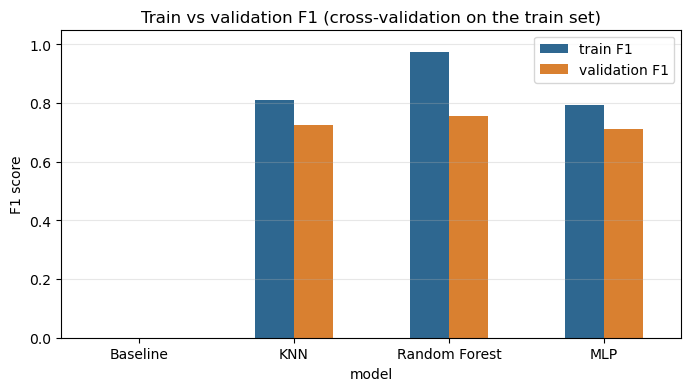

In [28]:
# Bars: train F1 and validation F1 for each model
cv_table[['train F1', 'validation F1']].plot.bar(figsize=(8, 4), rot=0, color=['#2E6790', '#D98030'])
plt.ylabel('F1 score')
plt.title('Train vs validation F1 (cross-validation on the train set)')
plt.ylim(0, 1.05)
plt.grid(axis='y', alpha=0.3)
plt.show()

**What to notice.** Look at the gap between the blue and the orange bar for each model. Which model has the largest gap? Which has the best orange bar? Is it the same model? A model with a large gap can still have the best validation score: the choice is made on the validation bar, and the gap is a diagnostic.

## 5.1 Balancing the classes

In this dataset the imbalance is moderate (38% / 62%), but the tool exists for severe cases, so let us see it. The simplest method: give more weight to the rare class during training, with `class_weight='balanced'`. An error on a survivor then costs more than an error on a passenger who died.

(The other method is oversampling: duplicating rows of the rare class. It needs great care: it must be done on the train rows only, inside each round of the cross-validation. Otherwise copies of the same row end up in train and validation, which is leakage. `class_weight` does not have this risk, because it changes nothing in the data.)

We compare the random forest with and without class weights, looking at precision and recall as well as F1. We limit the trees to `max_depth=5`: with fully grown trees every leaf is pure and the class weights have almost no effect.

In [29]:
# The same random forest without and with class weights ('balanced' gives more weight to the rare class)
rf_plain = make_pipeline(build_preprocess(), RandomForestClassifier(max_depth=5, random_state=42))
rf_balanced = make_pipeline(build_preprocess(), RandomForestClassifier(max_depth=5, class_weight='balanced', random_state=42))

# Precision, recall and F1 from the same cross-validation
rows = []
for name, est in {'Random Forest (max_depth=5)': rf_plain, 'Random Forest (max_depth=5), class_weight=balanced': rf_balanced}.items():
    res = cross_validate(est, X_train, y_train, cv=cv, scoring=['precision', 'recall', 'f1'])
    rows.append({'model': name,
                 'precision': res['test_precision'].mean(),
                 'recall': res['test_recall'].mean(),
                 'F1': res['test_f1'].mean()})

pd.DataFrame(rows).set_index('model').round(3)

,precision,recall,F1
model,,,
Random Forest (max_depth=5),0.826,0.695,0.755
"Random Forest (max_depth=5), class_weight=balanced",0.759,0.728,0.742


**What to notice.** With the balanced weights the recall usually goes up and the precision goes down a little: the model finds more survivors, at the cost of more false alarms. Here the imbalance is moderate, so the changes are modest. With a severe imbalance it would be large.

# Part 6 - Tune the hyperparameters

> **What we do:** search for better hyperparameters, with a validation curve and with grid searches.
>
> **Why:** the default values are not guaranteed to be good for our data. The search uses the validation scores, so the test set is not involved.

**Rule: choose hyperparameters with cross-validation, never with the test set.**

Recall: **parameters** are learned by `fit`; **hyperparameters** are chosen by us before `fit` (`max_depth` of the trees, `n_neighbors` of KNN, ...). So far we used the default values, or values chosen by hand. Are they good? We now look for better ones, using only the train set.

## 6.1 One hyperparameter: the validation curve

A hyperparameter often controls the **capacity** of the model: how complicated a rule it can express. For a random forest, `max_depth` limits the depth of the trees. A `validation_curve` runs the cross-validation for several values of one hyperparameter, and gives the train score and the validation score for each value.

A technical detail: in a pipeline, a hyperparameter is named `step__parameter`. The random forest step is called `randomforestclassifier` (the lowercase name of the class), so the name is `randomforestclassifier__max_depth`.

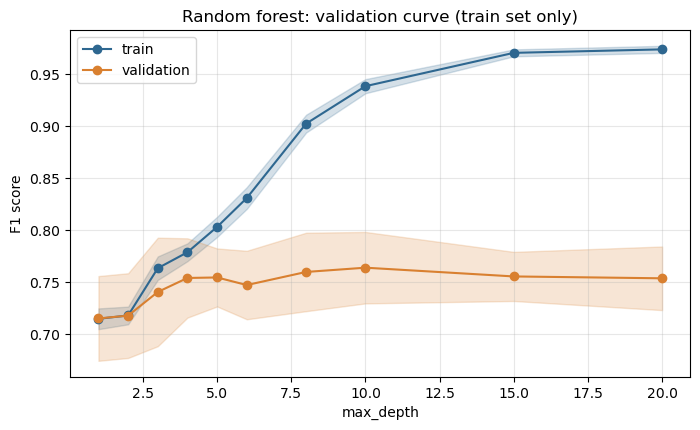

In [30]:
# The values of max_depth to try
depths = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20]

# For each depth: a cross-validation, returning the train and validation scores of the 5 rounds
train_sc, val_sc = validation_curve(
    candidates['Random Forest'], X_train, y_train,
    param_name='randomforestclassifier__max_depth', param_range=depths,
    cv=cv, scoring='f1')

# Plot the mean of the 5 rounds, with a band of one std above and below
plt.figure(figsize=(8, 4.5))
for sc, label, color in [(train_sc, 'train', '#2E6790'), (val_sc, 'validation', '#D98030')]:
    plt.plot(depths, sc.mean(axis=1), 'o-', label=label, color=color)
    plt.fill_between(depths, sc.mean(axis=1) - sc.std(axis=1), sc.mean(axis=1) + sc.std(axis=1),
                     alpha=0.2, color=color)
plt.xlabel('max_depth')
plt.ylabel('F1 score')
plt.title('Random forest: validation curve (train set only)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**How to read the curve.** The bands show the spread over the 5 rounds.

- On the **left** (small depth) both curves are low: the trees are too simple, underfitting.
- Moving **right**, the train curve keeps rising: more capacity always fits the train set better.
- The **validation** curve rises, then flattens or falls. The point where it stops improving is where more capacity stops helping.
- The **gap** between the two curves on the right is the overfitting.

A good choice is the *smallest* depth where the validation curve is already as high as it gets.

## 6.2 Two hyperparameters at once: grid search

Real models have several hyperparameters, and they interact. A **grid search** tries every combination from a grid of values that we write down:

- for **each combination**, it runs a full cross-validation (5 fits and 5 validation scores)
- it keeps the combination with the best mean validation score
- at the end it **refits** the model with the best combination on the whole train set (`refit=True` is the default)

So the cross-validation evaluates one combination, and the grid search repeats it for all combinations and compares them. The test set is not involved.

For the random forest we search over `max_depth` (6 values) and `min_samples_leaf` (5 values), the minimum number of passengers in each leaf of a tree. 6 x 5 = 30 combinations, each with 5 fits: it can take up to a minute.

In [31]:
# The grid: every combination of these values will be tried (6 x 5 = 30)
param_grid_rf = {
    'randomforestclassifier__max_depth': [2, 3, 4, 5, 6, 8],
    'randomforestclassifier__min_samples_leaf': [1, 3, 5, 10, 20],
}

# For each combination: a 5-fold cross-validation scored with F1 (n_jobs=-1 uses all the CPU cores)
gs_rf = GridSearchCV(candidates['Random Forest'], param_grid_rf, cv=cv, scoring='f1', n_jobs=-1)
# Run the search, on the train set only
gs_rf.fit(X_train, y_train)

# The winning combination and its mean validation F1
print("Best combination:", gs_rf.best_params_)
print(f"Its mean validation F1: {gs_rf.best_score_:.3f}")

Best combination: {'randomforestclassifier__max_depth': 5, 'randomforestclassifier__min_samples_leaf': 5}
Its mean validation F1: 0.762


**What to notice.** `fit` on a `GridSearchCV` runs all the cross-validations. The two attributes we use are `best_params_` (the winning combination) and `best_score_` (its mean validation F1).

One caveat: `best_score_` is the *best* of 30 noisy scores, so it is slightly optimistic. This is one more reason to keep a test set.

All the results are stored in `cv_results_`. A heatmap shows the whole grid at once.

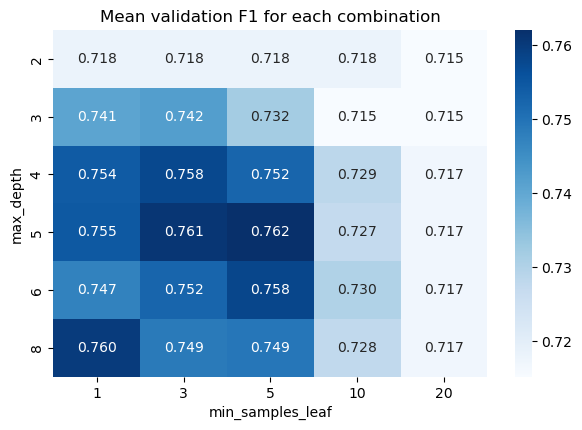

In [32]:
# All the results of the search, one row per combination
results = pd.DataFrame(gs_rf.cv_results_)
results['max_depth'] = results['param_randomforestclassifier__max_depth'].astype(int)
results['min_samples_leaf'] = results['param_randomforestclassifier__min_samples_leaf'].astype(int)

# Reshape to a grid: rows = max_depth, columns = min_samples_leaf
heat = results.pivot(index='max_depth', columns='min_samples_leaf', values='mean_test_score')

# Draw the grid as a heatmap
plt.figure(figsize=(7, 4.5))
sns.heatmap(heat, annot=True, fmt='.3f', cmap='Blues')
plt.title('Mean validation F1 for each combination')
plt.show()

**What to notice.** Each cell is one combination. Dark cells are better. Look at whether the good region is a single point or a wide area: if the neighbours of the best cell are almost as good, the choice is not critical.

## 6.3 The same for KNN

For KNN there is one main hyperparameter, `n_neighbors`: how many neighbours vote. A small k follows the noise (high capacity), a large k smooths too much (low capacity).

Best combination: {'kneighborsclassifier__n_neighbors': 15}
Its mean validation F1: 0.754


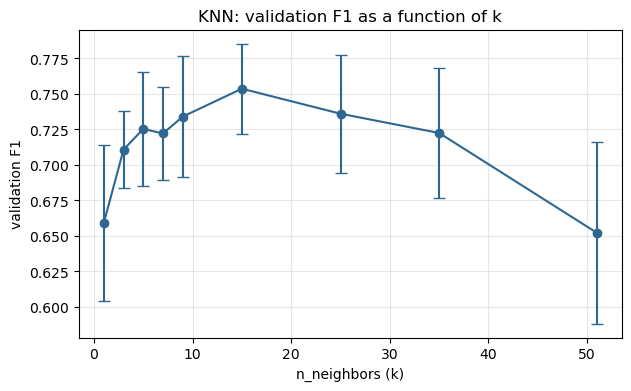

In [33]:
# The values of k to try
param_grid_knn = {'kneighborsclassifier__n_neighbors': [1, 3, 5, 7, 9, 15, 25, 35, 51]}

# Same procedure as before, now for KNN
gs_knn = GridSearchCV(candidates['KNN'], param_grid_knn, cv=cv, scoring='f1', n_jobs=-1)
gs_knn.fit(X_train, y_train)

print("Best combination:", gs_knn.best_params_)
print(f"Its mean validation F1: {gs_knn.best_score_:.3f}")

# Plot the validation F1 for each k, with the std over the 5 rounds as bars
res_knn = pd.DataFrame(gs_knn.cv_results_)
k_values = res_knn['param_kneighborsclassifier__n_neighbors'].astype(int)

plt.figure(figsize=(7, 4))
plt.errorbar(k_values, res_knn['mean_test_score'], yerr=res_knn['std_test_score'],
             fmt='o-', capsize=4, color='#2E6790')
plt.xlabel('n_neighbors (k)')
plt.ylabel('validation F1')
plt.title('KNN: validation F1 as a function of k')
plt.grid(alpha=0.3)
plt.show()

**What to notice.** The bars are the standard deviation over the 5 rounds. When two values of k differ by less than the bars, the difference is small compared with the variation between rounds, and we cannot rely on it.

We keep the tuned random forest and the tuned KNN. The MLP keeps the settings we chose by hand in Part 4 (tuning it would take longer, and the idea is the same).

# Part 7 - Seeds and spread

> **What we do:** repeat the cross-validation with different seeds, and compare the models on the spread of the scores.
>
> **Why:** a score from one single cut of the data can be lucky or unlucky. A mean and a spread tell us how much we can trust a comparison.

**Rule: set the seeds. Report a mean and a spread.**

All the scores so far come from one particular way of cutting the train set in 5 parts (`random_state=42`). A different seed cuts the parts differently and gives different scores. How much do the scores depend on this choice? Let us check with the tuned random forest and five different seeds.

In [34]:
# The tuned random forest (already refitted by the grid search)
rf_best = gs_rf.best_estimator_

# Repeat the 5-fold cross-validation with 5 different seeds
for seed in range(5):
    cv_seed = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    # clone: a fresh, unfitted copy, so that every evaluation starts from scratch
    scores = cross_val_score(clone(rf_best), X_train, y_train, cv=cv_seed, scoring='f1', n_jobs=-1)
    print(f"seed {seed}: mean validation F1 = {scores.mean():.3f}")

seed 0: mean validation F1 = 0.742
seed 1: mean validation F1 = 0.755
seed 2: mean validation F1 = 0.735
seed 3: mean validation F1 = 0.730
seed 4: mean validation F1 = 0.756


**What to notice.** The mean changes with the seed. A single cross-validation is one draw from a distribution of possible results. The honest report is a mean and a spread over many draws.

`RepeatedStratifiedKFold` does this automatically: it repeats the whole 5-fold cross-validation several times with different cuts. Here, 5 repetitions give 25 scores for each model. We compare the three tuned models.

`clone(...)` gives a fresh, unfitted copy of a model with the same hyperparameters, so that every evaluation starts from scratch.

In [35]:
# The three models we compare: tuned KNN, tuned random forest, MLP
tuned = {
    'KNN': gs_knn.best_estimator_,
    'Random Forest': gs_rf.best_estimator_,
    'MLP': candidates['MLP'],
}

# 5-fold cross-validation repeated 5 times with different cuts: 25 scores for each model
repeated_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)

repeated = {}
for name, est in tuned.items():
    repeated[name] = cross_val_score(clone(est), X_train, y_train, cv=repeated_cv, scoring='f1', n_jobs=-1)

# Mean and std of the 25 scores of each model
summary = pd.DataFrame({name: {'mean F1': s.mean(), 'std F1': s.std()} for name, s in repeated.items()}).T.round(3)
summary

,mean F1,std F1
KNN,0.737,0.044
Random Forest,0.753,0.034
MLP,0.721,0.046


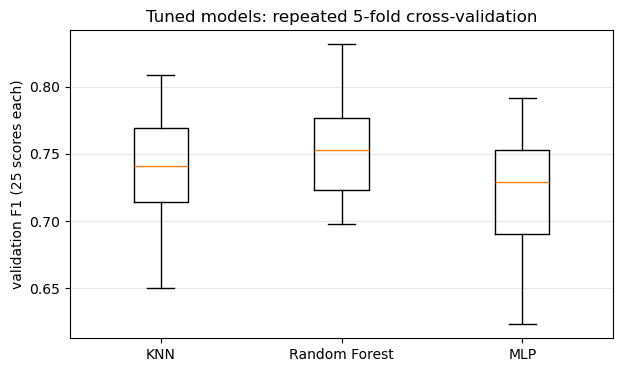

In [36]:
# One box per model: it summarises its 25 scores (median, quartiles, range)
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot(list(repeated.values()))
ax.set_xticklabels(list(repeated.keys()))
ax.set_ylabel('validation F1 (25 scores each)')
ax.set_title('Tuned models: repeated 5-fold cross-validation')
ax.grid(axis='y', alpha=0.3)
plt.show()

**What to notice.** Each box contains 25 scores. If two boxes overlap a lot, the two models are not clearly different, and in a real project we would prefer the simpler one.

Here we apply the simplest rule: we choose the model with the best mean. This choice used only the train set.

# Part 8 - The final evaluation, once

> **What we do:** refit the chosen model on the whole train set and score it on the test set.
>
> **Why:** this is the estimate of the performance on new passengers, the number we would report. It is honest only if the test set was never used before.

**Rule: the test set is scored once, at the end.**

We refit the chosen model on the whole train set, and for the first time we use the test set. This number is our estimate of the performance on new passengers.

If we now went back, changed something and ran the test again, the test set would become one more validation set and the estimate would no longer be honest. So: **one time**. After this evaluation we only *describe* the chosen model (Part 9): we never change anything because of what we see.

In [37]:
# The model with the best mean F1 in the repeated cross-validation (train set only)
best_name = summary['mean F1'].idxmax()
print("Chosen model:", best_name)

# Refit it on the whole train set
final_model = clone(tuned[best_name]).fit(X_train, y_train)

# For the first time, the test set: predicted classes and predicted probability of 'survived'
y_pred = final_model.predict(X_test)
y_proba = final_model.predict_proba(X_test)[:, 1]     # the probability of "survived"

print()
# Compare the cross-validated estimate with the test estimate
print(f"Cross-validated F1 (train set):  {summary.loc[best_name, 'mean F1']:.3f} +/- {summary.loc[best_name, 'std F1']:.3f}")
print(f"Test F1 (scored once):           {f1_score(y_test, y_pred):.3f}")
print(f"Test accuracy (scored once):     {accuracy_score(y_test, y_pred):.3f}")
print(f"Test ROC-AUC (scored once):      {roc_auc_score(y_test, y_proba):.3f}")

Chosen model: Random Forest

Cross-validated F1 (train set):  0.753 +/- 0.034
Test F1 (scored once):           0.718
Test accuracy (scored once):     0.810
Test ROC-AUC (scored once):      0.863


**What to notice.** The cross-validated F1 and the test F1 should be close. If they were very different, something would be wrong in the procedure (for example, a leak). A small difference is normal: the test set has only a few hundred rows, so its score has its own uncertainty.

## 8.1 Reading the errors

Three views of the same result.

**The classification report** lists precision, recall and F1 for each class.

**The confusion matrix** counts the answers: rows are the true classes, columns are the predicted ones. The diagonal is correct, the off-diagonal cells are the errors.

**The ROC curve** shows what happens when we change the threshold on the predicted probability. The model gives a probability of survival for each passenger, and so far we answered "survived" when it was at least 0.5. If we lower the threshold we find more survivors (higher recall) but we also raise more false alarms. The ROC curve plots recall against the false-alarm rate, for all the thresholds. The dashed diagonal is a coin toss. The **AUC** is the area under the curve: 0.5 is chance, 1.0 is perfect.

              precision    recall  f1-score   support

        died      0.800     0.921     0.856       165
    survived      0.833     0.631     0.718       103

    accuracy                          0.810       268
   macro avg      0.817     0.776     0.787       268
weighted avg      0.813     0.810     0.803       268



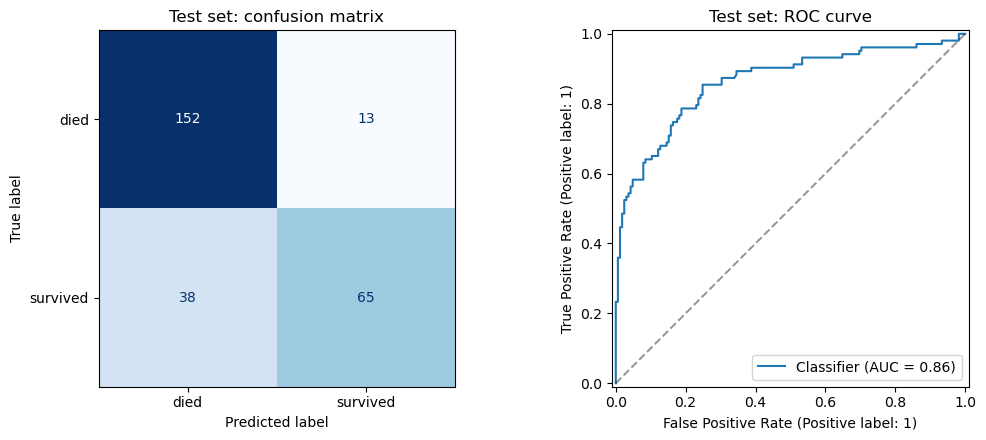

In [38]:
# Precision, recall and F1 for each class
print(classification_report(y_test, y_pred, target_names=['died', 'survived'], digits=3))

# Left: confusion matrix. Right: ROC curve (the dashed line is a coin toss)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['died', 'survived'],
                                        ax=axes[0], colorbar=False, cmap='Blues')
RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.4)
axes[0].set_title('Test set: confusion matrix')
axes[1].set_title('Test set: ROC curve')
plt.tight_layout()
plt.show()

### Check yourself

1. In the confusion matrix, which cell contains the survivors that the model missed? Which cell contains the false alarms?
2. Is the result better than the baseline of Part 3?
3. Suppose the test F1 is a bit different from the cross-validated F1 (a bit lower or a bit higher). Is this a problem?

<details>
<summary>Answers</summary>
<ol>
<li>The missed survivors are in the row "survived", column "died" (false negatives). The false alarms are in the row "died", column "survived" (false positives).</li>
<li>The baseline has F1 = 0 and accuracy of about 0.62: any reasonable model beats it clearly.</li>
<li>Not by itself. A small gap, in either direction, is expected: the test set is small, so its score has its own uncertainty, and the cross-validation score is slightly optimistic (we picked the best model and the best hyperparameters on it). A very large gap would be a warning.</li>
</ol>
</details>

# Part 9 - What does the model use?

> **What we do:** measure which features the model relies on.
>
> **Why:** to understand the model and to sanity-check it: if it relied on a feature that makes no sense, we would suspect a problem.

A model is built to **predict**, but we are often curious about which features it relies on. A simple method is **permutation importance**:

1. take the test set (already evaluated in Part 8) and measure the score
2. shuffle the values of *one* feature, so that its link with the label is destroyed, and measure the score again
3. the drop in the score tells us how much the model relied on that feature
4. repeat for each feature, and several times for each, to get a spread

We use the test set here only to describe a model that is already evaluated. Nothing we decide depends on this analysis. We would not use it to select features and then score the test set again.

`permutation_importance` works on the pipeline, so the features are the original columns: `sex`, `age`, ...

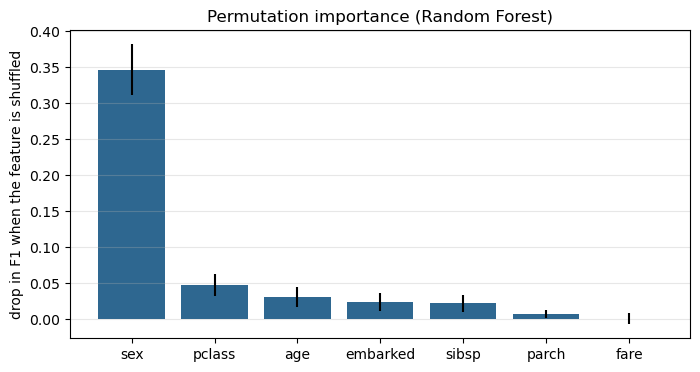

In [39]:
# Shuffle each feature 20 times and see how much the F1 drops
imp = permutation_importance(final_model, X_test, y_test, scoring='f1',
                             n_repeats=20, random_state=42)

# Sort the features from the most to the least important
order = imp.importances_mean.argsort()[::-1]

# Bars: the mean drop in F1, with the std over the 20 shuffles as a line
plt.figure(figsize=(8, 4))
plt.bar(X_test.columns[order], imp.importances_mean[order], yerr=imp.importances_std[order], color='#2E6790')
plt.ylabel('drop in F1 when the feature is shuffled')
plt.title(f'Permutation importance ({best_name})')
plt.grid(axis='y', alpha=0.3)
plt.show()

**What to notice.** The features with the tallest bars are the ones the model uses most. Compare with the bar plots of Part 1: do they agree?

**A caution.** Importance describes the *model*, not the world. It says that the model carries information about survival in these columns, not that these columns *cause* survival. Two correlated features can also share their importance, and each looks smaller than it is. In this course we say "carries information", never "causes".

# Part 10 - What we did

> **What we do:** look back at the order of the steps.
>
> **Why:** the order is the real content of the lesson: every step protects the honest estimate of the performance on new data, or helps to build a better model.

We followed the whole "Good practices" list of Lesson 2:

| Rule | Where in this notebook |
|---|---|
| Always doubt: what does the number measure, on which data, compared with what? | every score is a validation or a test score, with a baseline |
| Look at the data first | Part 1 |
| Split first, stratified. The test set is scored once | Part 2 and Part 8 |
| Set the seeds. Report a mean and a spread | `random_state` everywhere, Parts 3 and 7 |
| Compare train and validation scores | Parts 5 and 6 |
| Compare with a baseline. Look beyond accuracy | Part 3 and Part 8 |
| Balance the classes on the train set only | `class_weight` in Part 5 |
| Rescale inside a pipeline, fitted on the train set only | Part 4 |
| Choose hyperparameters with cross-validation, not with the test set | Part 6 |
| A perfect score is a warning, not a result | the scores here are good but not perfect, as in real life |

The skeleton is always the same:

> look at the data, split, baseline, pipeline, cross-validate, tune, final test once